# Figure 4g. Spatial layer expression of *cis*-neuronal and *trans*-glial genes

Layer differential expression in 32 ROSMAP DLPFC Visium sections, run per section and summarised per gene across sections. Left: *cis*-neuronal genes (neuron-only *cis*-eGenes at loci that also have glia-only *trans*-eGenes); x = median logFC of Deep (L4-L6) vs Outer (L1-L3) layers, y = -log10 of the median P across sections; colour = direction for genes with FDR < 0.05 in at least one section (all 123 genes pass this, so no "NS" genes remain). Right: glia-only *trans*-eGenes; for each layer group (one-vs-rest) the median P is taken over sections where the gene is up-regulated with FDR < 0.05 (0 if none); x = min(Deep, Outer), y = white matter. Labels: top 6 genes by -log10 P (left) and by WM minus cortical (right). No formal test is shown.

Input: `data/Figure_4g_spatial_layer_de.rds`

In [1]:
library(ggplot2)
library(ggrepel)
library(patchwork)
res <- readRDS("data/Figure_4g_spatial_layer_de.rds")
lapply(res, head)

$cis_neuron
      gene       logFC neglog10p      min_fdr n_samples de_layer
1     ADD1  0.06916668  3.683421 3.605604e-17        32     Deep
2     AFF3  0.02258539  1.123083 5.928788e-09        20     Deep
3     ANLN  0.06736890 10.051189 6.912362e-24        27     Deep
4    AP2B1  0.04742165  2.322784 8.020158e-18        32     Deep
5    APMAP  0.06164462  2.217201 9.237373e-16        31     Deep
6 ARHGEF26 -0.02030570  1.047820 2.528348e-02         3    Outer

$trans_glia
   gene neglog10p_deep neglog10p_outer neglog10p_cortical neglog10p_wm
1   A2M       2.483435        8.467146           2.483435     0.000000
2  AACS       9.415214        3.700054           3.700054     5.404720
3  AAMP       5.968301        2.904639           2.904639     0.000000
4  AATK       6.963755        3.322418           3.322418     9.560822
5  ABAT       7.720730        3.511568           3.511568     0.000000
6 ABCA2       2.881082        0.000000           0.000000    20.755815

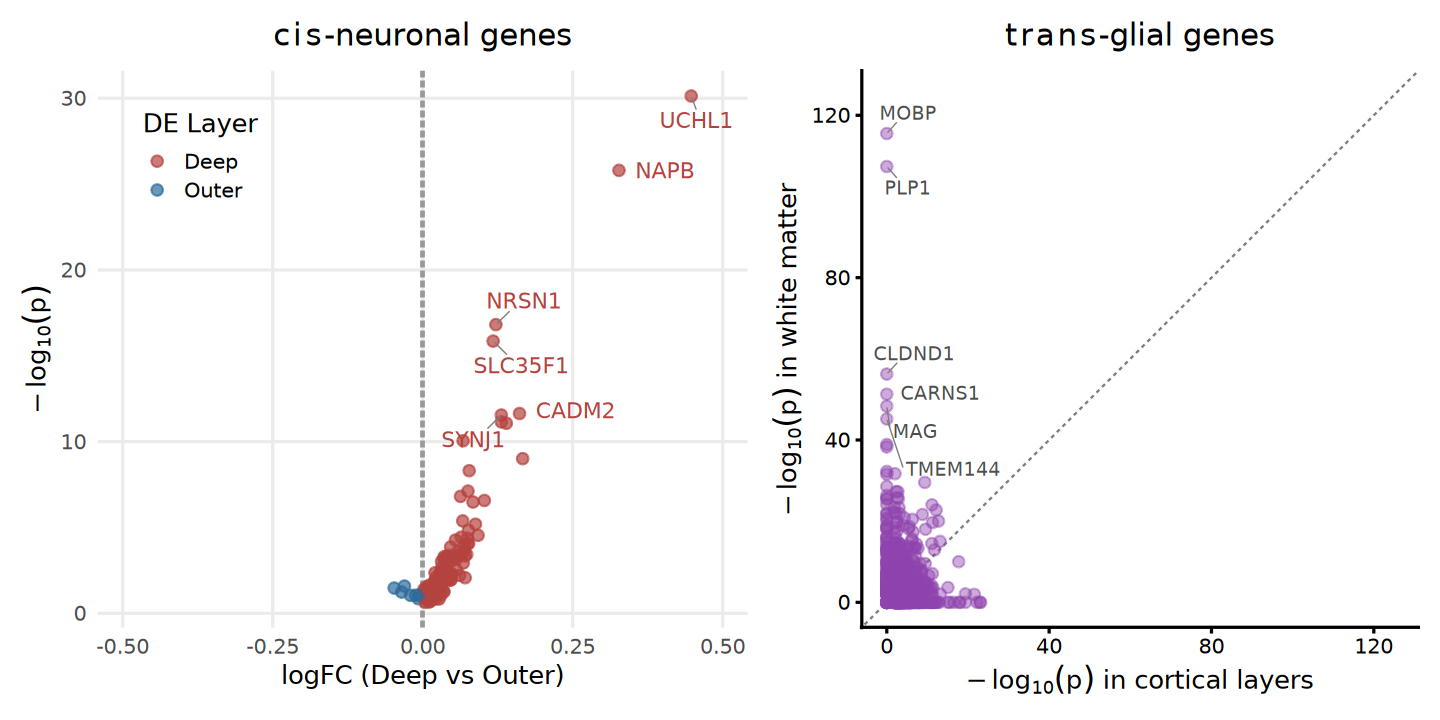

In [2]:
cis_df <- res$cis_neuron
top_cis <- head(subset(cis_df[order(-cis_df$neglog10p), ], de_layer == "Deep"), 6)
xlim_val <- max(abs(cis_df$logFC)) * 1.1

p_cis <- ggplot(cis_df, aes(x = logFC, y = neglog10p, colour = de_layer)) +
  geom_vline(xintercept = 0, linetype = "longdash", colour = "grey60", linewidth = 1) +
  geom_point(size = 2.5, alpha = 0.7) +
  geom_text_repel(data = top_cis, aes(label = gene), colour = "#B5423E", size = 4.5,
                  box.padding = 0.6, segment.colour = "grey50", segment.size = 0.3,
                  nudge_x = 0.02, seed = 1) +
  scale_colour_manual(values = c("Deep" = "#B5423E", "Outer" = "#2B6A99"), name = "DE Layer") +
  scale_x_continuous(limits = c(-xlim_val, xlim_val)) +
  labs(title = expression(italic(cis) * "-neuronal genes"),
       x = "logFC (Deep vs Outer)", y = expression(-log[10](p))) +
  theme_minimal(base_size = 15) +
  theme(plot.title = element_text(hjust = 0.5),
        legend.position = "inside", legend.position.inside = c(0.05, 0.95),
        legend.justification = c(0, 1), panel.grid.minor = element_blank())

tg <- res$trans_glia
tg$diff <- tg$neglog10p_wm - tg$neglog10p_cortical
top_tg <- head(tg[order(-tg$diff), ], 6)
lim <- max(c(tg$neglog10p_cortical, tg$neglog10p_wm)) * 1.08

p_trans <- ggplot(tg, aes(x = neglog10p_cortical, y = neglog10p_wm)) +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed", colour = "grey50", linewidth = 0.5) +
  geom_point(alpha = 0.45, size = 2.5, colour = "#8E44AD") +
  geom_text_repel(data = top_tg, aes(label = gene), size = 4, colour = "grey30",
                  box.padding = 0.5, segment.colour = "grey50", segment.size = 0.3, seed = 1) +
  scale_x_continuous(limits = c(0, lim)) +
  scale_y_continuous(limits = c(0, lim)) +
  coord_fixed() +
  labs(title = expression(italic(trans) * "-glial genes"),
       x = expression(-log[10](p) ~ "in cortical layers"),
       y = expression(-log[10](p) ~ "in white matter")) +
  theme_classic(base_size = 15) +
  theme(plot.title = element_text(hjust = 0.5))

options(repr.plot.width = 12, repr.plot.height = 6)
p_cis + p_trans